# code_208 · Report the axis along which a structure is new

**Book:** section 39.3. Restart and run all cells. Imports, helpers and generated observations are internal; ordinary execution is offline and CPU-only, with no credentials or files. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_39_GUIDE.md), [execution evidence](../CHAPTER_39_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_208).

Reference runtime: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0 and scikit-learn 1.9.0. Allow two minutes to execute and 45–90 minutes to interpret. Robustness contracts identify the source population, challenge mechanism, allowed adaptation information, physical checks and fallback. Original experiments expose metric behaviour; they are not benchmark reproductions or evidence that the generated law describes inspected structures. Simulator-only truth is labelled separately from observable assessment. No final score chooses a model or threshold. No dependency or asset is added.


In [1]:
import platform,time,json,copy
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn,threadpoolctl
from scipy.special import expit
from IPython.display import display
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=8008;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print(platform.system(),platform.machine(),'CPU; seed',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':10,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
Darwin arm64 CPU; seed 8008


## Separate the direction of extrapolation
 Generate independent scalar chains with n free nodes, n identical springs, a fixed node0 and a unit nodal mass. Axial rigidity EA divided by member length gives stiffness. The complex frequency-domain system is (K-omega²I+i0.04omegaI)u=f, with harmonic tip load q. Report tip displacement amplitude in declared reference displacement units. Source1,000 chains use n3–6, EA5–8, length0.8–1.2, q0.5–1.5 and omega0–0.1. Fit100-iteration HGB to the five raw attributes. Independently fit one nonnegative multiplicative calibration coefficient to the known physical solver response. This comparator uses correct equations as privileged modelling knowledge, not learned discovery. Assess200 new entities per predeclared regime: familiar, n9–12, length1.8–2.2, EA1–2, q3–5, or omega0.5–0.9. Only one axis changes at a time.


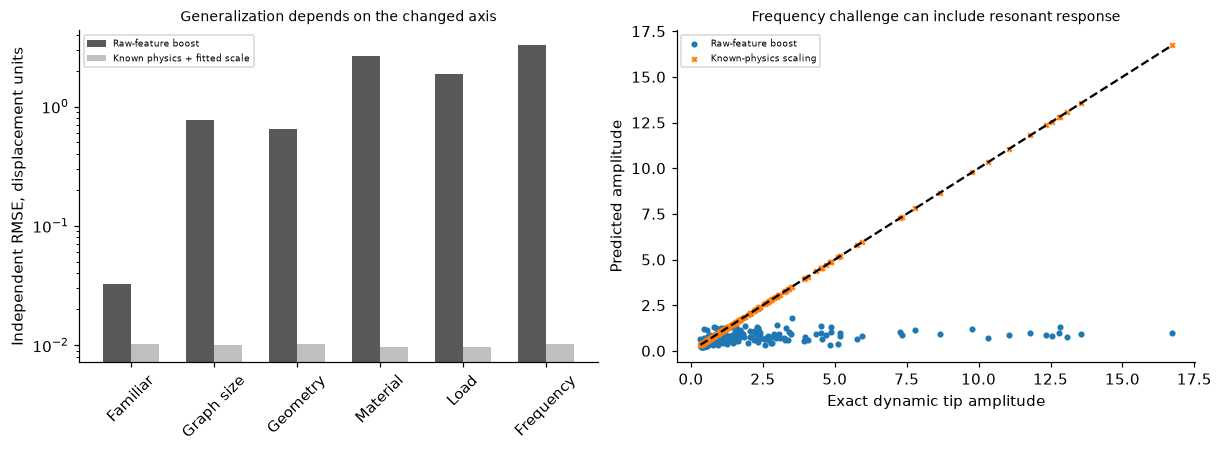

In [2]:
from sklearn.ensemble import HistGradientBoostingRegressor
def physical(x,extra_support=False):
    out=[]
    for row in x:
        n=int(row[0]);EA,L,q,omega=row[1:];k=EA/L;inc=np.zeros((n,n))
        for e in range(n):
            inc[e,e]=1
            if e:inc[e,e-1]=-1
        K=k*inc.T@inc
        if extra_support:K[-1,-1]+=k
        force=np.zeros(n);force[-1]=q;u=np.linalg.solve(K-omega**2*np.eye(n)+1j*.04*omega*np.eye(n),force);out.append(abs(u[-1]))
    return np.array(out)
def cohort(n,regime='Familiar'):
    x=np.c_[rng.integers(3,7,n),rng.uniform(5,8,n),rng.uniform(.8,1.2,n),rng.uniform(.5,1.5,n),rng.uniform(0,.1,n)]
    if regime=='Graph size':x[:,0]=rng.integers(9,13,n)
    if regime=='Geometry':x[:,2]=rng.uniform(1.8,2.2,n)
    if regime=='Material':x[:,1]=rng.uniform(1,2,n)
    if regime=='Load':x[:,3]=rng.uniform(3,5,n)
    if regime=='Frequency':x[:,4]=rng.uniform(.5,.9,n)
    truth=physical(x);return x,truth+rng.normal(scale=.01,size=n),truth
xs,ys,ps=cohort(1000);model=HistGradientBoostingRegressor(max_iter=100,max_depth=3,early_stopping=False,random_state=SEED).fit(xs,ys);scale=max(0.,float(ps@ys/(ps@ps)));regimes=['Familiar','Graph size','Geometry','Material','Load','Frequency'];scores={};assess={}
for name in regimes:
    x,y,true=cohort(200,name);raw=model.predict(x);hybrid=scale*physical(x);scores[name]={'entities':200,'raw_RMSE':float(np.sqrt(np.mean((raw-y)**2))),'physical_scaling_RMSE':float(np.sqrt(np.mean((hybrid-y)**2))),'true_tip_range':[float(true.min()),float(true.max())]};assess[name]=(x,y,true,raw,hybrid)
assert scale>=0;assert all(np.isfinite(v['raw_RMSE']) for v in scores.values());assert assess['Graph size'][0][:,0].min()>xs[:,0].max();RESULTS.update(source_entities=1000,source_graph_sizes=[3,6],learned_physical_scale=scale,axis_challenge_scores=scores,solver_is_privileged_known_equation=True);fig,axes=plt.subplots(1,2,figsize=(11,4));xx=np.arange(6)
for j,(field,label) in enumerate([('raw_RMSE','Raw-feature boost'),('physical_scaling_RMSE','Known physics + fitted scale')]):axes[0].bar(xx+(j-.5)*.34,[scores[k][field] for k in regimes],.34,label=label,color=['.35','.75'][j])
axes[0].set(xticks=xx,xticklabels=regimes,yscale='log',ylabel='Independent RMSE, displacement units',title='Generalization depends on the changed axis');axes[0].tick_params(axis='x',rotation=45);axes[0].legend(fontsize=6);x,y,true,raw,hybrid=assess['Frequency'];axes[1].scatter(true,raw,s=9,label='Raw-feature boost');axes[1].scatter(true,hybrid,s=9,marker='x',label='Known-physics scaling');lo,hi=true.min(),true.max();axes[1].plot([lo,hi],[lo,hi],color='black',linestyle='--');axes[1].set(xlabel='Exact dynamic tip amplitude',ylabel='Predicted amplitude',title='Frequency challenge can include resonant response');axes[1].legend(fontsize=6);plt.show()


## A physical prior transfers only while its boundary conditions remain valid
 Generate200 additional familiar-attribute chains but attach a positive spring from the tip to ground. Solve the changed matrix, retaining identical visible raw attributes. The raw feature model and the assumed-free-tip physics comparator do not receive this new support metadata. Compare their errors with a solver explicitly given the extra support. The latter is an oracle model-consistency reference, not an adapted learner validated from target observations. Also check exact force scaling and invariance to a mere entity identifier: a new identifier alone is not a new mechanical regime. Separate conditional-mechanism change from size/material interpolation and disclose the missing support variable.


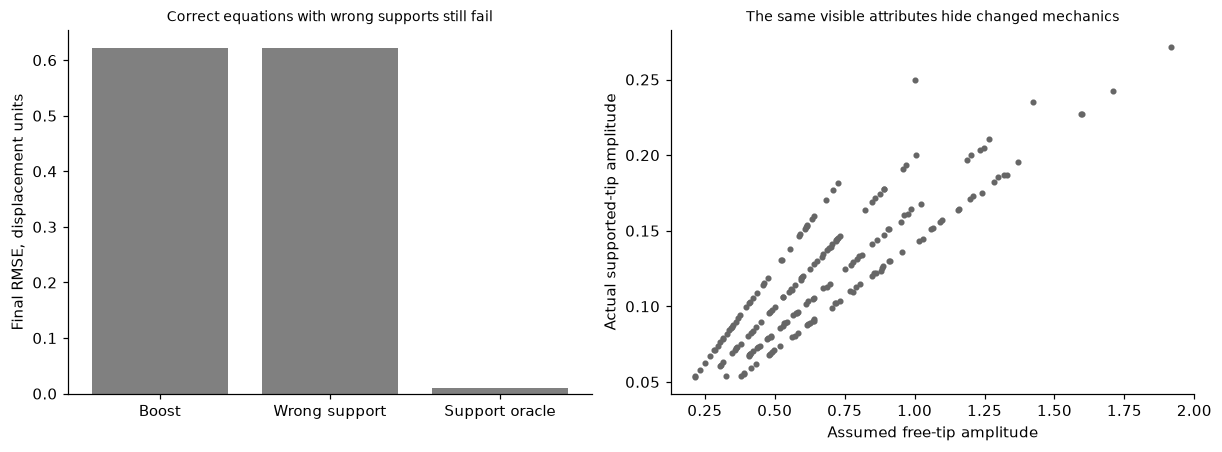

In [3]:
bx,_,_=cohort(200);true_changed=physical(bx,extra_support=True);observed=true_changed+rng.normal(scale=.01,size=200);wrong_physics=scale*physical(bx);correct_physics=scale*physical(bx,extra_support=True);boundary_scores={'Raw-feature boost':float(np.sqrt(np.mean((model.predict(bx)-observed)**2))),'Assumed free tip physics':float(np.sqrt(np.mean((wrong_physics-observed)**2))),'Support-informed oracle physics':float(np.sqrt(np.mean((correct_physics-observed)**2)))};doubled=bx.copy();doubled[:,3]*=2;assert np.allclose(physical(doubled),2*physical(bx));assert np.allclose(physical(bx.copy()),physical(bx));assert np.all(true_changed<physical(bx));RESULTS.update(changed_support_RMSE=boundary_scores,extra_support_omitted_from_predictor_inputs=True,linear_force_scaling_checked=True,changed_support_oracle_is_not_adapted_model=True);fig,axes=plt.subplots(1,2,figsize=(11,4));axes[0].bar(range(3),list(boundary_scores.values()),color='.5');axes[0].set(xticks=range(3),xticklabels=['Boost','Wrong support','Support oracle'],ylabel='Final RMSE, displacement units',title='Correct equations with wrong supports still fail');axes[1].scatter(physical(bx),true_changed,s=9,color='.4');axes[1].set(xlabel='Assumed free-tip amplitude',ylabel='Actual supported-tip amplitude',title='The same visible attributes hide changed mechanics');plt.show()


In [4]:
summary={'example_id':'code_208','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual frequency-domain elastic chain solver with independent source/final entities', 'separate graph size member length material load and frequency challenges', 'learned physical response scaling contrasted with raw feature boosting', 'changed boundary-condition challenge exposes misspecified physical transfer'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual frequency-domain elastic chain solver with independent source/final entities", "separate graph size member length material load and frequency challenges", "learned physical response scaling contrasted with raw feature boosting", "changed boundary-condition challenge exposes misspecified physical transfer"], "elapsed_seconds": 0.522, "example_id": "code_208", "hardware": "Darwin arm64 CPU", "results": {"axis_challenge_scores": {"Familiar": {"entities": 200, "physical_scaling_RMSE": 0.010179451199069293, "raw_RMSE": 0.03291299374355887, "true_tip_range": [0.17258687551017587, 1.9722826428612268]}, "Frequency": {"entities": 200, "physical_scaling_RMSE": 0.010159823920644394, "raw_RMSE": 3.2478536719872966, "true_tip_range": [0.32947434004853604, 16.71966840882771]}, "Geometry": {"entities": 200, "physical_scaling_RMSE": 0.010215114580141248, "raw_RMSE": 0.6502689436869811, "true_tip_range": [0.5340442201670573, 3.100325965673381]},